# Module 3 — Les word embeddings

> **Objectif** : comprendre comment des mots deviennent des **vecteurs denses** dont la géométrie encode le sens : mots proches = vecteurs proches, relations = directions (« roi − homme + femme ≈ reine »). On construit des embeddings de deux façons, par **comptage** (PPMI + SVD) puis par **prédiction** (word2vec skip-gram avec échantillonnage négatif, codé de zéro en NumPy, gradients compris), et on voit comment les utiliser dans PyTorch.

| | |
|---|---|
| **Durée estimée** | 2 h 30 |
| **Prérequis** | Modules 0 à 2 |
| **Librairies** | `numpy`, `matplotlib`, `scikit-learn` ; `torch` pour la section 8 |

**Plan**

1. Pourquoi le one-hot ne suffit pas
2. L'hypothèse distributionnelle
3. Un corpus-jouet avec une sémantique contrôlée
4. Approche par comptage : co-occurrences, PPMI, SVD
5. word2vec : skip-gram et échantillonnage négatif (maths complètes)
6. word2vec de zéro en NumPy
7. Explorer l'espace : voisins, analogies, visualisation, vrai corpus
8. Les embeddings dans PyTorch
9. Limites : polysémie, biais, et l'arrivée des embeddings contextuels
10. Récapitulatif et exercices

In [1]:
import re
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

## 1. Pourquoi le one-hot ne suffit pas

Au module 2, chaque mot était un **vecteur one-hot** $e_i\in\{0,1\}^V$ : un 1 à la position du mot, des 0 ailleurs. Deux défauts rédhibitoires :

1. **Aucune notion de similarité** : pour deux mots différents, $e_i^\top e_j = 0$. « chat » est exactement aussi éloigné de « chien » que de « démocratie ». Ce que le modèle apprend sur « excellent » ne se transfère jamais à « formidable ».
2. **Dimension énorme** : $V$ = 50 000 composantes pour représenter un mot.

**L'idée** : représenter chaque mot par un vecteur **dense** de petite dimension $d$ (50 à 1 000), appris de façon à ce que des mots qui « se comportent pareil » aient des vecteurs proches. Une **matrice d'embeddings** $E\in\mathbb R^{V\times d}$ contient un vecteur par mot ; l'embedding du mot $i$ est la ligne $E_i$, c'est-à-dire $e_i^\top E$ (le one-hot sélectionne une ligne).

## 2. L'hypothèse distributionnelle

> *« You shall know a word by the company it keeps. »* — J. R. Firth, 1957

Si je te dis : « Le *wampimuk* grimpe aux arbres et mange des bananes », tu devines que c'est un animal, probablement un primate, sans jamais avoir vu le mot. **Le sens d'un mot se déduit de ses contextes.** Deux mots qui apparaissent dans des contextes similaires ont un sens similaire (Harris, 1954).

Toutes les méthodes d'embeddings exploitent cette idée : elles transforment des **statistiques de co-occurrence** en géométrie. Elles diffèrent seulement par la manière de le faire.

## 3. Un corpus-jouet avec une sémantique contrôlée

Pour **voir** clairement ce qui est appris, on génère un corpus dont on connaît la structure cachée :
- des **personnes** avec trois attributs : genre (m/f), statut (royal/noble/peuple), âge (adulte/jeune). Chaque attribut a ses propres mots de contexte (« il », « robe », « couronne », « champs », « école »…) ;
- des **pays** avec leur capitale, leur langue et leur continent ;
- des **animaux** avec leur nourriture et leur habitat ; des **fruits**.

Si l'hypothèse distributionnelle tient, les embeddings appris devraient retrouver ces attributs **sans qu'on les ait jamais donnés explicitement**. On passera à un vrai corpus en section 7.

In [2]:
PEOPLE = {  # word: (gender, status, age)
    "roi": ("m", "royal", "adulte"), "reine": ("f", "royal", "adulte"),
    "prince": ("m", "royal", "jeune"), "princesse": ("f", "royal", "jeune"),
    "duc": ("m", "noble", "adulte"), "duchesse": ("f", "noble", "adulte"),
    "homme": ("m", "peuple", "adulte"), "femme": ("f", "peuple", "adulte"),
    "garçon": ("m", "peuple", "jeune"), "fille": ("f", "peuple", "jeune"),
}
GENDER_CTX = {"m": ["il", "lui", "barbe", "monsieur", "son_épouse"], "f": ["elle", "robe", "madame", "enceinte", "son_mari"]}
STATUS_CTX = {"royal": ["couronne", "trône", "palais", "royaume", "sujets", "règne"],
              "noble": ["château", "domaine", "blason", "chasse", "bal", "titre"],
              "peuple": ["champs", "marché", "village", "travail", "salaire", "atelier"]}
AGE_CTX = {"adulte": ["mariage", "impôts", "vieux", "sage", "enfants"], "jeune": ["école", "jouer", "parents", "petit", "jouets"]}
COUNTRIES = {"france": ("paris", "français", "europe"), "italie": ("rome", "italien", "europe"),
             "espagne": ("madrid", "espagnol", "europe"), "allemagne": ("berlin", "allemand", "europe"),
             "portugal": ("lisbonne", "portugais", "europe"), "japon": ("tokyo", "japonais", "asie"),
             "chine": ("pékin", "chinois", "asie"), "brésil": ("brasilia", "portugais", "amérique"),
             "mexique": ("mexico", "espagnol", "amérique"), "canada": ("ottawa", "anglais", "amérique")}
ANIMALS = {"chat": ("croquettes", "maison"), "chien": ("os", "maison"), "lapin": ("carottes", "maison"),
           "lion": ("viande", "savane"), "tigre": ("viande", "jungle"), "vache": ("herbe", "ferme"),
           "mouton": ("herbe", "ferme"), "cheval": ("foin", "ferme")}
FRUITS = ["pomme", "poire", "banane", "fraise", "cerise", "orange", "raisin", "pêche"]
FILLERS = ["le", "la", "de", "et", "avec", "dans"]


def make_sentence(r):
    k = r.random()
    if k < 0.45:                                    # a person + one context word per attribute
        w = r.choice(list(PEOPLE)); g, s, a = PEOPLE[w]
        ctx = [r.choice(GENDER_CTX[g]), r.choice(STATUS_CTX[s]), r.choice(AGE_CTX[a])]
        r.shuffle(ctx)
        out = [r.choice(FILLERS), ctx[0], r.choice(FILLERS), ctx[1]]
        out.insert(r.integers(0, len(out) + 1), w)
        return out + [r.choice(FILLERS), ctx[2]]
    if k < 0.70:                                    # countries, capitals, languages
        c = r.choice(list(COUNTRIES)); cap, lang, cont = COUNTRIES[c]
        return [[cap, "est", "la", "capitale", "de", c], ["à", cap, "on", "parle", lang],
                ["en", c, "on", "parle", lang], [r.choice([c, cap]), "se", "trouve", "en", cont]][r.integers(0, 4)]
    if k < 0.85:
        a = r.choice(list(ANIMALS)); food, habitat = ANIMALS[a]
        return ["le", a, r.choice(["mange", "aime", "dévore"]), "des", food, "à", "la", habitat]
    f = r.choice(FRUITS)
    return ["la", f, "est", r.choice(["mûre", "sucrée", "juteuse", "fraîche"]), "en", r.choice(["jus", "tarte", "confiture", "salade"])]


r = np.random.default_rng(0)
sentences = [make_sentence(r) for _ in range(60_000)]
sentences = [[str(w) for w in s] for s in sentences]      # numpy str_ -> plain str
corpus = [w for s in sentences for w in s]
for s in sentences[:6]:
    print(" ".join(s))
vocab = [w for w, _ in Counter(corpus).most_common()]
stoi = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
ids = np.array([stoi[w] for w in corpus])
counts = np.bincount(ids, minlength=V)
print(f"\n{len(corpus):,} tokens, vocabulary of {V} words")

à tokyo on parle japonais
et il dans roi sage et sujets
la cerise est sucrée en salade
princesse dans son_mari la école dans royaume
à paris on parle français
et il la duc mariage avec château

393,899 tokens, vocabulary of 131 words


## 4. Approche par comptage : co-occurrences, PPMI, SVD

### 📐 Maths

1. **Matrice de co-occurrence** $C\in\mathbb N^{V\times V}$ : $C_{wc}$ = nombre de fois où le mot de contexte $c$ apparaît dans une fenêtre de $\pm L$ mots autour de $w$.
2. Les comptes bruts sont dominés par les mots fréquents (« le », « de »). On les remplace par l'**information mutuelle ponctuelle** (PMI), qui mesure si $w$ et $c$ co-occurrent **plus que par hasard** :
$$
\text{PMI}(w,c) = \log\frac{p(w,c)}{p(w)\,p(c)}
$$
$\text{PMI}>0$ : association ; $=0$ : indépendance ; $<0$ : évitement. Les valeurs négatives étant très bruitées, on les tronque : $\text{PPMI} = \max(\text{PMI}, 0)$.
3. **Réduction de dimension** par décomposition en valeurs singulières tronquée : $\text{PPMI}\approx U_d\Sigma_d V_d^\top$, et on prend $E = U_d\Sigma_d^{1/2}$ comme embeddings de dimension $d$. C'est l'**analyse sémantique latente** (LSA, 1990), l'ancêtre des embeddings.

In [3]:
def cooccurrence(sentences, stoi, window=2):
    C = np.zeros((len(stoi), len(stoi)))
    for s in sentences:
        idx = [stoi[w] for w in s]
        for i, wi in enumerate(idx):
            for j in range(max(0, i - window), min(len(idx), i + window + 1)):
                if j != i:
                    C[wi, idx[j]] += 1
    return C

C = cooccurrence(sentences, stoi)
P = C / C.sum()
pw = P.sum(1, keepdims=True); pc = P.sum(0, keepdims=True)
with np.errstate(divide="ignore"):
    PMI = np.log(P / (pw * pc))
PPMI = np.maximum(PMI, 0)

U, S, Vt = np.linalg.svd(PPMI)
d = 20
E_svd = U[:, :d] * np.sqrt(S[:d])

def nearest(E, word, k=5):
    En = E / np.linalg.norm(E, axis=1, keepdims=True)
    sims = En @ En[stoi[word]]
    return [(vocab[i], round(float(sims[i]), 2)) for i in np.argsort(-sims)[1:k + 1]]

for w in ["roi", "chat", "paris", "pomme"]:
    print(f"{w:6s} -> {nearest(E_svd, w)}")

roi    -> [('prince', 0.77), ('reine', 0.52), ('bal', 0.48), ('chasse', 0.46), ('blason', 0.46)]
chat   -> [('lapin', 1.0), ('chien', 1.0), ('cheval', 1.0), ('lion', 1.0), ('tigre', 1.0)]
paris  -> [('mexico', 1.0), ('rome', 1.0), ('pékin', 1.0), ('madrid', 1.0), ('berlin', 1.0)]
pomme  -> [('orange', 1.0), ('fraise', 1.0), ('cerise', 1.0), ('pêche', 1.0), ('banane', 1.0)]


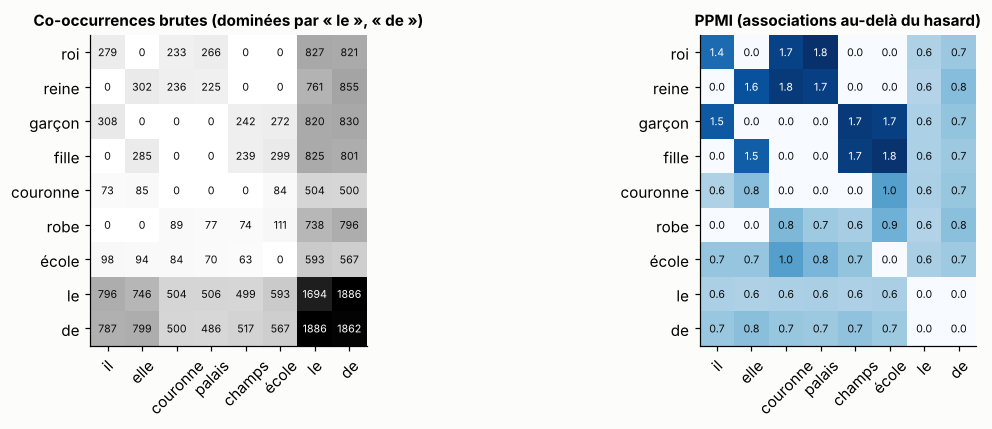

In [4]:
words_show = ["roi", "reine", "garçon", "fille", "couronne", "robe", "école", "le", "de"]
ctx_show = ["il", "elle", "couronne", "palais", "champs", "école", "le", "de"]
sub_C = C[np.ix_([stoi[w] for w in words_show], [stoi[c] for c in ctx_show])]
sub_P = PPMI[np.ix_([stoi[w] for w in words_show], [stoi[c] for c in ctx_show])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, M, title, cm in [(axes[0], sub_C, "Co-occurrences brutes (dominées par « le », « de »)", "Greys"),
                         (axes[1], sub_P, "PPMI (associations au-delà du hasard)", "Blues")]:
    ax.imshow(M, cmap=cm)
    ax.set_xticks(range(len(ctx_show))); ax.set_xticklabels(ctx_show, rotation=45)
    ax.set_yticks(range(len(words_show))); ax.set_yticklabels(words_show)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f"{v:.0f}" if M is sub_C else f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.6 * M.max() else "#0b0b0b")
    ax.set_title(title, fontsize=10); ax.grid(False)
plt.tight_layout(); plt.show()

**Problème de passage à l'échelle** : $C$ est de taille $V\times V$. Pour $V = 10^5$, c'est $10^{10}$ cases, et la SVD coûte $O(V^3)$. D'où l'intérêt d'une méthode qui apprend **directement** les vecteurs en parcourant le texte : word2vec.

## 5. word2vec : skip-gram et échantillonnage négatif

### 💡 Intuition

Plutôt que de compter, on pose une **tâche de prédiction factice** : « étant donné un mot, prédire les mots de son voisinage ». On ne se soucie pas de la qualité des prédictions ; ce qui nous intéresse, ce sont les **vecteurs appris en chemin**. Pour réussir, le modèle doit donner des vecteurs similaires aux mots qui ont des voisinages similaires : exactement l'hypothèse distributionnelle.

C'est la première apparition d'une idée qui domine le NLP moderne : **l'apprentissage auto-supervisé**. Le texte fournit lui-même les étiquettes. BERT et GPT reposent sur le même principe, à une autre échelle.

### 📐 Le modèle skip-gram (Mikolov et al., 2013)

Chaque mot $w$ a **deux** vecteurs : $v_w$ quand il est au centre, $u_w$ quand il est en contexte. Pour un mot central $c$ et un mot de contexte $o$ (dans une fenêtre de $\pm L$) :

$$
p(o\mid c) = \frac{\exp(u_o^\top v_c)}{\sum_{w=1}^{V}\exp(u_w^\top v_c)}
$$

C'est une softmax sur tout le vocabulaire (module 0) avec les logits $u_w^\top v_c$. On maximise $\sum \log p(o\mid c)$ sur toutes les paires (centre, contexte) du corpus.

**Le problème** : le dénominateur somme sur $V$ mots, à **chaque** paire. Avec $V = 10^5$ et des milliards de paires, c'est prohibitif.

### 📐 L'échantillonnage négatif (SGNS)

On remplace la classification à $V$ classes par une **classification binaire** : « la paire $(c, o)$ est-elle une vraie paire du corpus, ou une paire tirée au hasard ? » Pour chaque vraie paire, on tire $K$ mots « négatifs » $n_1,\dots,n_K$ (typiquement $K = 5$ à $20$) et on minimise :

$$
\ell(c,o) = -\log\sigma(u_o^\top v_c) - \sum_{k=1}^{K}\log\sigma(-u_{n_k}^\top v_c)
$$

Premier terme : rapprocher $v_c$ du vrai contexte. Second terme : l'éloigner des contextes tirés au hasard. Le coût passe de $O(V)$ à $O(K)$ par paire.

**Les gradients** (avec $\sigma'(x)=\sigma(x)(1-\sigma(x))$ et $\frac{d}{dx}\log\sigma(x) = 1-\sigma(x)$, cf. module 0) :

$$
\begin{aligned}
\frac{\partial \ell}{\partial v_c} &= \big(\sigma(u_o^\top v_c)-1\big)\,u_o + \sum_{k}\sigma(u_{n_k}^\top v_c)\,u_{n_k}\\
\frac{\partial \ell}{\partial u_o} &= \big(\sigma(u_o^\top v_c)-1\big)\,v_c\\
\frac{\partial \ell}{\partial u_{n_k}} &= \sigma(u_{n_k}^\top v_c)\,v_c
\end{aligned}
$$

On retrouve la forme « prédiction − vérité » : pour la vraie paire la cible est 1, d'où $\sigma - 1$ ; pour les négatifs elle est 0, d'où $\sigma - 0$.

### Deux astuces qui comptent beaucoup

1. **Distribution de bruit** : les négatifs sont tirés selon $P_n(w)\propto \text{count}(w)^{0.75}$. L'exposant $0.75$ (trouvé empiriquement) aplatit la distribution : les mots rares sont tirés un peu plus souvent que leur fréquence.
2. **Sous-échantillonnage des mots fréquents** : chaque occurrence d'un mot de fréquence $f(w)$ est gardée avec probabilité $\min\left(1, \sqrt{t/f(w)} + t/f(w)\right)$, avec $t\approx 10^{-3}$ à $10^{-5}$. « le » et « de » apportent peu d'information et sont massivement éliminés ; cela accélère l'entraînement **et** élargit la fenêtre effective.

> 📎 **Ce que word2vec fait vraiment** (Levy & Goldberg, 2014) : à l'optimum, SGNS factorise implicitement la matrice $\text{PMI}(w,c) - \log K$. Les deux approches de ce module, comptage et prédiction, sont donc les deux faces d'une même idée. **GloVe** (Pennington et al., 2014) rend ce lien explicite en ajustant directement $u_w^\top v_c + b_w + b_c \approx \log C_{wc}$ par moindres carrés pondérés.

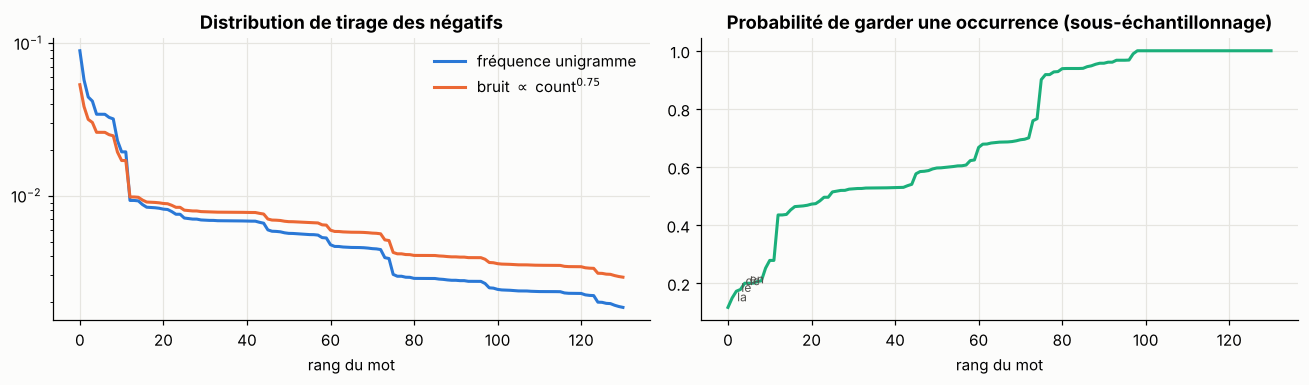

In [5]:
freq = counts / counts.sum()
noise = counts ** 0.75; noise /= noise.sum()
t = 1e-3
p_keep = np.minimum(1.0, np.sqrt(t / freq) + t / freq)

order = np.argsort(-counts)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].semilogy(freq[order], label="fréquence unigramme")
axes[0].semilogy(noise[order], label=r"bruit $\propto$ count$^{0.75}$")
axes[0].set_title("Distribution de tirage des négatifs"); axes[0].set_xlabel("rang du mot"); axes[0].legend()
axes[1].plot(p_keep[order], color=PALETTE[2])
for i in range(4):
    axes[1].annotate(vocab[order[i]], (i, p_keep[order[i]]), xytext=(6, 4), textcoords="offset points", fontsize=8, color="#52514e")
axes[1].set_title("Probabilité de garder une occurrence (sous-échantillonnage)"); axes[1].set_xlabel("rang du mot")
plt.tight_layout(); plt.show()

## 6. word2vec de zéro en NumPy

On vectorise le calcul sur des mini-batchs de paires : pour $B$ paires et $K$ négatifs, les produits scalaires deviennent des `einsum` sur des tenseurs `(B, K, d)`. `np.add.at` accumule correctement les mises à jour quand un même mot apparaît plusieurs fois dans le batch (une simple indexation `W[idx] -= g` perdrait les doublons : c'est l'équivalent NumPy de l'accumulation des gradients de `nn.Embedding`).

In [6]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def make_pairs(ids, p_keep, window, r):
    kept = ids[r.random(len(ids)) < p_keep[ids]]           # subsampling, redrawn each epoch
    centers, contexts = [], []
    for off in range(1, window + 1):                        # all (center, context) pairs within the window
        centers += [kept[:-off], kept[off:]]
        contexts += [kept[off:], kept[:-off]]
    return np.concatenate(centers), np.concatenate(contexts)


def train_sgns(ids, V, d=30, window=2, K=5, epochs=4, lr=0.05, batch=256, seed=0, verbose=True):
    r = np.random.default_rng(seed)
    W_in = (r.random((V, d)) - 0.5) / d                     # center vectors v_w
    W_out = np.zeros((V, d))                                # context vectors u_w
    history = []
    for ep in range(epochs):
        c_all, o_all = make_pairs(ids, p_keep, window, r)
        perm = r.permutation(len(c_all)); c_all, o_all = c_all[perm], o_all[perm]
        total = 0.0
        for s in range(0, len(c_all), batch):
            c, o = c_all[s:s + batch], o_all[s:s + batch]
            n = r.choice(V, size=(len(c), K), p=noise)      # negatives
            vc, uo, un = W_in[c], W_out[o], W_out[n]        # (B,d), (B,d), (B,K,d)
            s_pos = sigmoid((vc * uo).sum(1))               # (B,)
            s_neg = sigmoid(np.einsum("bkd,bd->bk", un, vc))  # (B,K)
            total -= np.log(s_pos + 1e-10).sum() + np.log(1 - s_neg + 1e-10).sum()
            g_pos = (s_pos - 1)[:, None]                    # sigma - 1
            grad_vc = g_pos * uo + np.einsum("bk,bkd->bd", s_neg, un)
            grad_uo = g_pos * vc
            grad_un = s_neg[..., None] * vc[:, None, :]
            np.add.at(W_in, c, -lr * grad_vc)
            np.add.at(W_out, o, -lr * grad_uo)
            np.add.at(W_out, n.ravel(), -lr * grad_un.reshape(-1, d))
        history.append(total / len(c_all))
        if verbose:
            print(f"epoch {ep}: mean loss per pair {history[-1]:.4f} ({len(c_all):,} pairs)")
    return W_in, W_out, history


W_in, W_out, hist = train_sgns(ids, V)
E_w2v = W_in
print("\nrandom-guess reference loss (sigma=0.5 everywhere): (K+1)*log 2 =", round(6 * np.log(2), 3))

epoch 0: mean loss per pair 2.4372 (697,022 pairs)
epoch 1: mean loss per pair 2.4072 (696,974 pairs)
epoch 2: mean loss per pair 2.4078 (694,202 pairs)
epoch 3: mean loss per pair 2.4058 (696,502 pairs)

random-guess reference loss (sigma=0.5 everywhere): (K+1)*log 2 = 4.159


> 🔍 La perte ne descend pas vers 0, et c'est normal : un même mot central a de nombreux contextes possibles, et les négatifs tirés au hasard sont parfois de vrais contextes. Ce qui compte est la géométrie obtenue, qu'on évalue ci-dessous.

## 7. Explorer l'espace des embeddings

### 7.1 Voisins les plus proches (similarité cosinus)

In [7]:
for w in ["roi", "reine", "chat", "paris", "pomme", "france", "école"]:
    print(f"{w:8s} -> {nearest(E_w2v, w)}")

roi      -> [('reine', 0.7), ('prince', 0.63), ('homme', 0.55), ('duc', 0.54), ('lisbonne', 0.49)]
reine    -> [('roi', 0.7), ('princesse', 0.69), ('elle', 0.53), ('bal', 0.49), ('sujets', 0.48)]
chat     -> [('lapin', 0.71), ('chien', 0.64), ('tigre', 0.61), ('cheval', 0.55), ('mouton', 0.52)]
paris    -> [('france', 0.78), ('français', 0.69), ('madrid', 0.6), ('italie', 0.54), ('pékin', 0.52)]
pomme    -> [('fraise', 0.85), ('banane', 0.83), ('raisin', 0.82), ('cerise', 0.82), ('poire', 0.8)]
france   -> [('paris', 0.78), ('français', 0.68), ('italie', 0.68), ('espagne', 0.59), ('madrid', 0.55)]
école    -> [('jouets', 0.89), ('jouer', 0.87), ('parents', 0.83), ('petit', 0.79), ('avec', 0.67)]


### 7.2 Analogies : les relations sont des directions

Si les embeddings encodent les attributs de façon **additive**, alors $v_{\text{roi}} - v_{\text{homme}}$ isole « royauté » (le genre s'annule), et y ajouter $v_{\text{femme}}$ devrait tomber près de $v_{\text{reine}}$. On cherche :
$$
\arg\max_{w\notin\{a,b,c\}}\ \cos\left(v_w,\ v_b - v_a + v_c\right)
$$

In [8]:
def analogy(E, a, b, c, k=3):
    """a is to b as c is to ?"""
    En = E / np.linalg.norm(E, axis=1, keepdims=True)
    target = En[stoi[b]] - En[stoi[a]] + En[stoi[c]]
    sims = En @ target
    for w in (a, b, c):
        sims[stoi[w]] = -np.inf
    return [vocab[i] for i in np.argsort(-sims)[:k]]

tests = [("homme", "roi", "femme", "reine"), ("garçon", "prince", "fille", "princesse"),
         ("roi", "reine", "duc", "duchesse"), ("homme", "garçon", "roi", "prince"),
         ("france", "paris", "italie", "rome"), ("france", "paris", "japon", "tokyo"),
         ("japon", "japonais", "chine", "chinois"), ("paris", "français", "berlin", "allemand")]
for name, E in [("PPMI+SVD", E_svd), ("word2vec", E_w2v)]:
    ok = 0
    print(f"--- {name} ---")
    for a, b, c, expected in tests:
        top = analogy(E, a, b, c)
        ok += top[0] == expected
        print(f"  {b} - {a} + {c} = {top[0]:10s} {'✅' if top[0] == expected else '❌ (expected ' + expected + ')'}   top3={top}")
    print(f"  accuracy: {ok}/{len(tests)}")

--- PPMI+SVD ---
  roi - homme + femme = reine      ✅   top3=['reine', 'princesse', 'château']
  prince - garçon + fille = princesse  ✅   top3=['princesse', 'reine', 'et']
  reine - roi + duc = duchesse   ✅   top3=['duchesse', 'enfants', 'impôts']
  garçon - homme + roi = prince     ✅   top3=['prince', 'princesse', 'barbe']
  paris - france + italie = rome       ✅   top3=['rome', 'mexico', 'pékin']
  paris - france + japon = pékin      ❌ (expected tokyo)   top3=['pékin', 'mexico', 'madrid']
  japonais - japon + chine = chinois    ✅   top3=['chinois', 'anglais', 'portugais']
  français - paris + berlin = chinois    ❌ (expected allemand)   top3=['chinois', 'anglais', 'portugais']
  accuracy: 6/8
--- word2vec ---
  roi - homme + femme = reine      ✅   top3=['reine', 'duchesse', 'princesse']
  prince - garçon + fille = princesse  ✅   top3=['princesse', 'reine', 'petit']
  reine - roi + duc = duchesse   ✅   top3=['duchesse', 'enfants', 'robe']
  garçon - homme + roi = prince     ✅   top3=['

**Lecture critique des résultats :**
- Avec PPMI + SVD ($d=20$), les animaux, les fruits et les capitales ont tous des similarités ≈ 1.0 entre eux : la SVD tronquée garde les directions qui expliquent le plus de variance (les grandes catégories) et **écrase** les distinctions fines (quelle capitale va avec quel pays). D'où l'échec de « paris − france + japon ». Augmenter $d$ ou pondérer autrement les valeurs singulières change ce comportement (exercice 1).
- word2vec réussit presque tout, mais l'échec restant est instructif : pour « paris : français :: berlin : ? », il répond « allemagne » puis « allemand ». Les analogies sont **fragiles** : la bonne réponse est souvent dans le top 3 sans être en tête, car la relation « capitale → langue » passe par le pays et n'est pas une direction propre de l'espace.
- Sur des embeddings réels, les analogies célèbres marchent bien moins souvent que ce que suggère « roi − homme + femme = reine » ; plusieurs travaux ont montré que ce test surestime la structure réelle de l'espace. Ne t'en sers que comme indicateur grossier.

### 7.3 Visualisation

On projette les embeddings en 2D par **ACP** (analyse en composantes principales). Attention : on perd beaucoup d'information en passant de 30 à 2 dimensions ; une projection n'est qu'un indice.

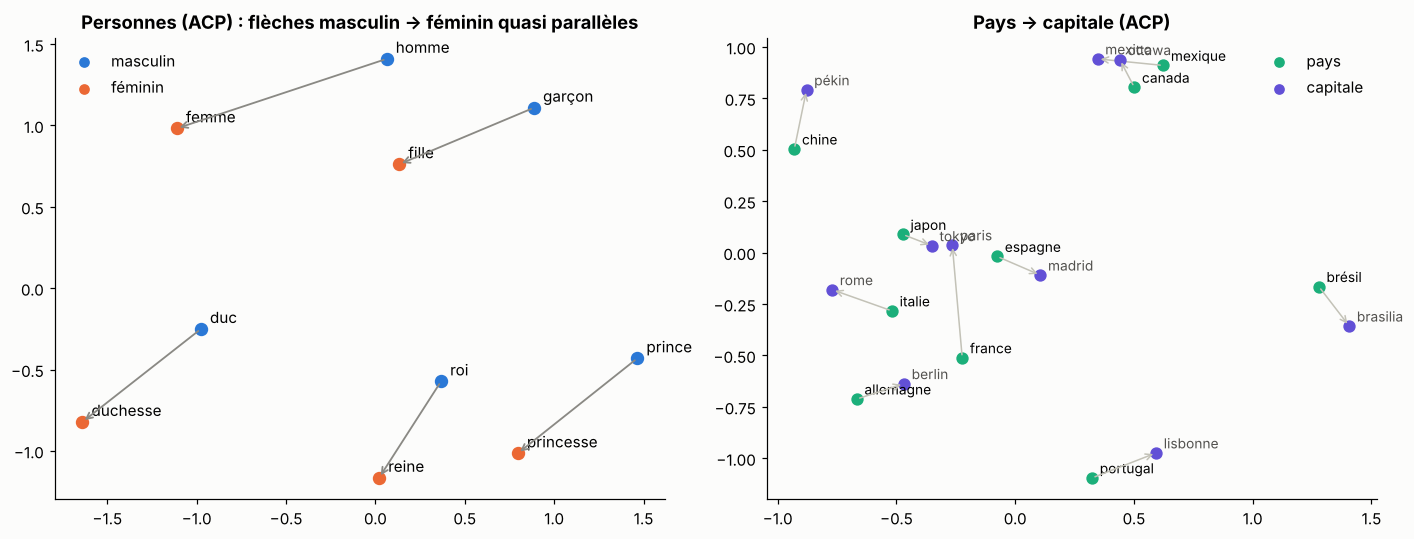

In [9]:
from sklearn.decomposition import PCA

people = list(PEOPLE)
pca = PCA(n_components=2).fit(E_w2v[[stoi[w] for w in people]])
Z = pca.transform(E_w2v[[stoi[w] for w in people]])
pos = dict(zip(people, Z))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
col = {"m": PALETTE[0], "f": PALETTE[1]}
for w in people:
    ax.scatter(*pos[w], s=60, color=col[PEOPLE[w][0]], zorder=3)
    ax.annotate(w, pos[w], xytext=(6, 4), textcoords="offset points", fontsize=10)
for m, f in [("roi", "reine"), ("prince", "princesse"), ("duc", "duchesse"), ("homme", "femme"), ("garçon", "fille")]:
    ax.annotate("", xy=pos[f], xytext=pos[m], arrowprops=dict(arrowstyle="->", color="#8a8984", lw=1.2))
ax.set_title("Personnes (ACP) : flèches masculin → féminin quasi parallèles"); ax.grid(False)
ax.scatter([], [], color=PALETTE[0], label="masculin"); ax.scatter([], [], color=PALETTE[1], label="féminin"); ax.legend(loc="best")

ax = axes[1]
geo = list(COUNTRIES) + [v[0] for v in COUNTRIES.values()]
Zg = PCA(n_components=2).fit_transform(E_w2v[[stoi[w] for w in geo]])
pg = dict(zip(geo, Zg))
for c_, (cap, _, _) in COUNTRIES.items():
    ax.scatter(*pg[c_], color=PALETTE[2], s=50, zorder=3); ax.scatter(*pg[cap], color=PALETTE[6], s=50, zorder=3)
    ax.annotate(c_, pg[c_], xytext=(5, 3), textcoords="offset points", fontsize=9)
    ax.annotate(cap, pg[cap], xytext=(5, 3), textcoords="offset points", fontsize=9, color="#52514e")
    ax.annotate("", xy=pg[cap], xytext=pg[c_], arrowprops=dict(arrowstyle="->", color="#c3c2b7", lw=1))
ax.scatter([], [], color=PALETTE[2], label="pays"); ax.scatter([], [], color=PALETTE[6], label="capitale"); ax.legend(loc="best")
ax.set_title("Pays → capitale (ACP)"); ax.grid(False)
plt.tight_layout(); plt.show()

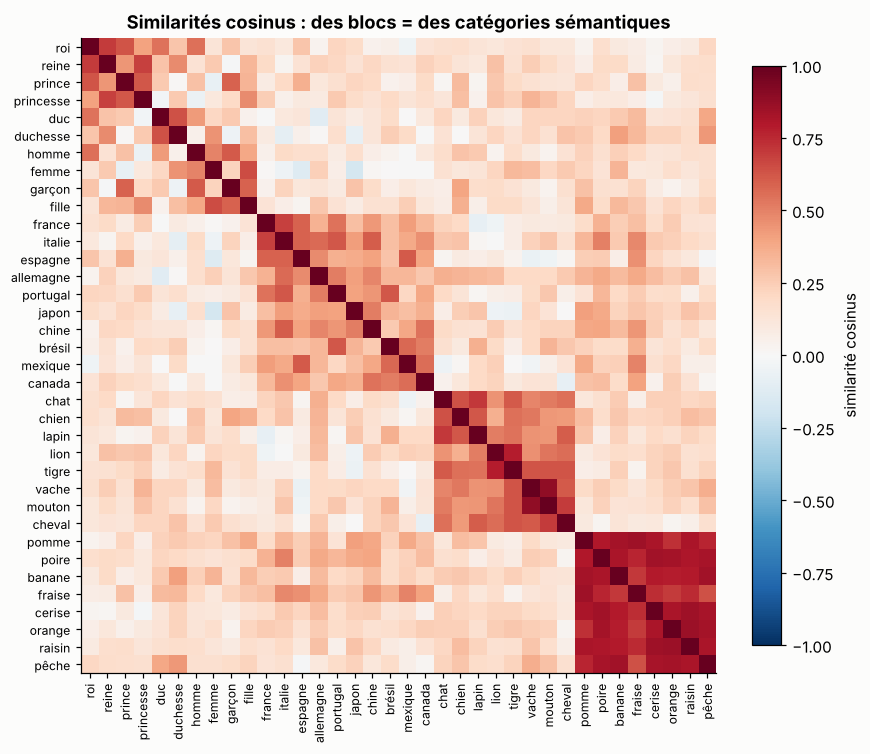

In [10]:
groups = {"personnes": list(PEOPLE), "pays": list(COUNTRIES), "animaux": list(ANIMALS), "fruits": FRUITS}
sel = [w for g in groups.values() for w in g]
En = E_w2v / np.linalg.norm(E_w2v, axis=1, keepdims=True)
Ssel = En[[stoi[w] for w in sel]] @ En[[stoi[w] for w in sel]].T
plt.figure(figsize=(8.5, 7.5))
plt.imshow(Ssel, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(sel)), sel, rotation=90, fontsize=8); plt.yticks(range(len(sel)), sel, fontsize=8)
plt.colorbar(fraction=0.04, label="similarité cosinus"); plt.grid(False)
plt.title("Similarités cosinus : des blocs = des catégories sémantiques")
plt.show()

### 7.4 Sur un vrai corpus

Rien de truqué : réentraînons exactement le même code sur la documentation Python du module 2 (corpus réel, anglais technique, ~75 000 mots).

In [11]:
from pydoc_data.topics import topics

raw = [t for t in re.findall(r"[a-z_]+", " ".join(topics.values()).lower()) if len(t) > 1]
c_raw = Counter(raw)
real_tokens = [t for t in raw if c_raw[t] >= 5]
vocab_backup = (vocab, stoi, counts, noise, p_keep)                 # keep the toy setup aside

vocab = [w for w, _ in Counter(real_tokens).most_common()]
stoi = {w: i for i, w in enumerate(vocab)}
ids_real = np.array([stoi[w] for w in real_tokens])
counts = np.bincount(ids_real, minlength=len(vocab))
freq = counts / counts.sum(); noise = counts ** 0.75; noise /= noise.sum()
p_keep = np.minimum(1.0, np.sqrt(t / freq) + t / freq)
print(f"{len(real_tokens):,} tokens | vocabulary {len(vocab):,}")
E_real, _, _ = train_sgns(ids_real, len(vocab), d=50, epochs=8, verbose=False)
for w in ["list", "int", "true", "raise", "dictionary", "method", "string", "zero"]:
    print(f"{w:11s} -> {[x for x, _ in nearest(E_real, w, 6)]}")
vocab, stoi, counts, noise, p_keep = vocab_backup                  # restore the toy setup

65,923 tokens | vocabulary 1,498
list        -> ['comprehension', 'display', 'yielded', 'constructed', 'formed', 'tuple']
int         -> ['simpleexpr', 'memoryview', 'bin', 'frozenset', 'float', 'oct']
true        -> ['false', 'isnumeric', 'isdigit', 'isalpha', 'isupper', 'isprintable']
raise       -> ['eg', 'blockingioerror', 'exc_info', 'exceptiongroup', 'oserror', 'overflowerror']
dictionary  -> ['view', 'new', 'dictview', 'update', 'creates', 'hashable']
method      -> ['overriding', '__add__', '__getattribute__', 'lookup', '__sub__', '__pow__']
string      -> ['raw', 'suffix', 'escapes', 'characters', 'therefore', 'zeros']
zero        -> ['positive', 'zerodivisionerror', 'ignore', 'coefficient', 'division', 'numeric_type']


Les voisins sont souvent pertinents (`int` → `float`, `frozenset`, `bin`… ; `true` → `false` ; `raise` → des noms d'exceptions), parfois étranges (`list` → `comprehension`, `display` : en Python on parle de *list comprehension* et de *list display*). C'est un point essentiel : **les embeddings capturent la co-occurrence, pas le « sens » au sens humain**. `true` et `false` sont voisins parce qu'ils apparaissent dans les mêmes contextes, bien qu'ils soient opposés : c'est vrai aussi de « bon »/« mauvais » dans les embeddings statiques, un piège pour l'analyse de sentiment.

## 8. Les embeddings dans PyTorch

### 8.1 `nn.Embedding` est un produit one-hot × matrice

$$
\text{Embedding}(i) = e_i^\top E = E_{i,:}
$$

C'est une couche linéaire sans biais appliquée à un one-hot, implémentée comme une simple **indexation** (beaucoup plus efficace). Son gradient est **creux** : seules les lignes des tokens présents dans le batch reçoivent un gradient.

In [12]:
E_toy = rng.normal(size=(5, 3))
i = 2
one_hot = np.eye(5)[i]
print("one-hot @ E :", (one_hot @ E_toy).round(3))
print("E[i]        :", E_toy[i].round(3))

one-hot @ E : [ 1.304  0.947 -0.704]
E[i]        : [ 1.304  0.947 -0.704]


### 8.2 SGNS en PyTorch

Avec autograd, plus besoin d'écrire les gradients à la main : il suffit d'écrire la perte.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class SkipGramNS(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.inp = nn.Embedding(V, d)          # v_w (center)
        self.out = nn.Embedding(V, d)          # u_w (context)
        nn.init.uniform_(self.inp.weight, -0.5 / d, 0.5 / d)
        nn.init.zeros_(self.out.weight)

    def forward(self, center, context, negatives):          # (B,), (B,), (B,K)
        vc = self.inp(center)                                # (B, d)
        pos = (vc * self.out(context)).sum(-1)               # (B,)
        neg = torch.bmm(self.out(negatives), vc.unsqueeze(-1)).squeeze(-1)   # (B, K)
        # -log sigma(x) = softplus(-x): numerically stable
        return (F.softplus(-pos) + F.softplus(neg).sum(-1)).mean()


torch.manual_seed(0)
sg = SkipGramNS(V, 30)
opt = torch.optim.Adam(sg.parameters(), lr=0.01)
noise_t = torch.tensor(noise, dtype=torch.float)
r_pt = np.random.default_rng(1)
for ep in range(3):
    c_all, o_all = make_pairs(ids, p_keep, 2, r_pt)
    c_all, o_all = torch.from_numpy(c_all), torch.from_numpy(o_all)
    perm = torch.randperm(len(c_all))
    for s in range(0, len(perm), 1024):
        idx = perm[s:s + 1024]
        negs = torch.multinomial(noise_t, len(idx) * 5, replacement=True).view(len(idx), 5)
        loss = sg(c_all[idx], o_all[idx], negs)
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"epoch {ep}: last batch loss {loss.item():.4f}")

E_torch = sg.inp.weight.detach().numpy()
print(nearest(E_torch, "roi"), analogy(E_torch, "homme", "roi", "femme"))

### 8.3 Utiliser des embeddings pré-entraînés dans un classifieur

Deux stratégies, qu'on retrouvera à grande échelle avec les Transformers (modules 7–8) :
- **geler** les embeddings (`freeze=True`) : peu de paramètres à apprendre, utile avec très peu de données ;
- les **affiner** (*fine-tuning*) avec le reste du modèle : meilleur avec assez de données, risque de sur-apprentissage sinon.

In [ ]:
pretrained = torch.tensor(E_w2v, dtype=torch.float)
emb_frozen = nn.Embedding.from_pretrained(pretrained, freeze=True)
emb_finetuned = nn.Embedding.from_pretrained(pretrained.clone(), freeze=False)
print(emb_frozen.weight.requires_grad, emb_finetuned.weight.requires_grad)

# In practice, for large pretrained vectors: gensim
# pip install gensim
# from gensim.models import Word2Vec
# w2v = Word2Vec(sentences=list_of_token_lists, vector_size=100, window=5, negative=5, sg=1, min_count=5, epochs=5)
# w2v.wv.most_similar("roi")

> 💡 **fastText** (Bojanowski et al., 2017) représente un mot comme la **somme des embeddings de ses n-grammes de caractères** (« <ro », « roi », « oi> »…). Résultat : un vecteur pour tout mot, même jamais vu, et une bien meilleure qualité pour les langues morphologiquement riches. C'est la même intuition que les sous-mots du module 2.

## 9. Limites des embeddings statiques

1. **Un seul vecteur par mot, quel que soit le contexte.** « avocat » (fruit / juriste), « souris » (animal / périphérique) : le vecteur est une moyenne des sens, pondérée par leur fréquence. Le contexte de la phrase ne change rien.
2. **Antonymes proches** : « bon »/« mauvais », `true`/`false` partagent leurs contextes.
3. **Biais sociaux** : les embeddings reproduisent les régularités du corpus, stéréotypes compris. Bolukbasi et al. (2016) montraient que des embeddings entraînés sur des articles de presse complétaient « homme : programmeur :: femme : ? » par « femme au foyer ». Notre corpus-jouet illustre le mécanisme : le genre y est une **direction** de l'espace (on l'estime en moyennant les différences « féminin − masculin » de 5 paires). Les mots qui co-occurrent avec un genre dans les données (« robe », « barbe ») se projettent fortement sur cette direction ; les mots neutres dans le corpus (« couronne », « chat ») restent près de 0. Si le corpus associait systématiquement un métier à un genre, ce métier serait projeté de la même manière : l'embedding ne fait qu'enregistrer les régularités, stéréotypes compris.

neighbours of 'roi' with W_in      : ['reine', 'prince', 'homme', 'duc', 'lisbonne']
neighbours of 'roi' with W_in+W_out: ['barbe', 'il', 'monsieur', 'royaume', 'trône']


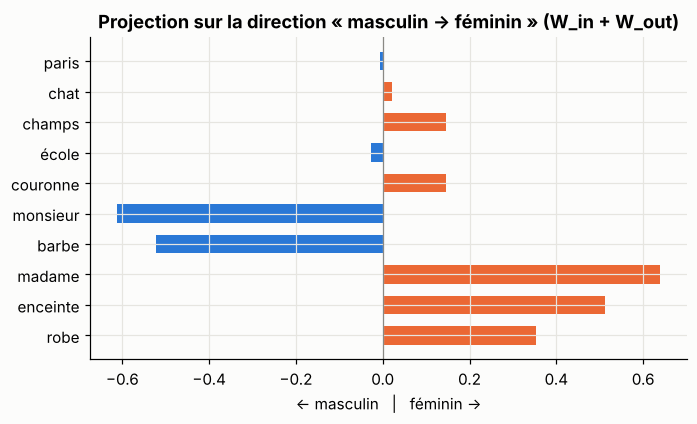

In [13]:
# W_in + W_out mixes "substitutable" and "co-occurring" similarity (see the note below)
E_sum = W_in + W_out
En = E_sum / np.linalg.norm(E_sum, axis=1, keepdims=True)
print("neighbours of 'roi' with W_in      :", [w for w, _ in nearest(W_in, "roi")])
print("neighbours of 'roi' with W_in+W_out:", [w for w, _ in nearest(E_sum, "roi")])
pairs = [("roi", "reine"), ("prince", "princesse"), ("duc", "duchesse"), ("homme", "femme"), ("garçon", "fille")]
gender_dir = np.mean([En[stoi[f]] - En[stoi[m]] for m, f in pairs], axis=0)   # average of 5 differences = less noise
gender_dir /= np.linalg.norm(gender_dir)
probe_words = ["robe", "enceinte", "madame", "barbe", "monsieur", "couronne", "école", "champs", "chat", "paris"]
proj = [En[stoi[w]] @ gender_dir for w in probe_words]
plt.figure(figsize=(7, 3.8))
plt.barh(probe_words, proj, color=[PALETTE[1] if p > 0 else PALETTE[0] for p in proj], height=0.6)
plt.axvline(0, color="#8a8984", lw=0.8)
plt.title("Projection sur la direction « masculin → féminin » (W_in + W_out)"); plt.xlabel("← masculin   |   féminin →")
plt.show()

> 🔬 **Deux types de similarité, deux matrices.** Avec $W_{in}$ seul, deux mots sont proches s'ils sont **substituables** (mêmes contextes : « roi » ≈ « reine », « prince ») : similarité *paradigmatique*. Le score $v_w^\top u_c$ entre $W_{in}$ et $W_{out}$ mesure au contraire la **co-occurrence** (« roi » avec « couronne », « barbe ») : similarité *syntagmatique*. Additionner $W_{in}+W_{out}$ (comme le fait GloVe) mélange les deux. Pour mesurer l'association d'un mot de contexte (« robe ») avec un genre, c'est la co-occurrence qui compte, d'où l'usage de $W_{in}+W_{out}$ ici. Avec $W_{in}$ seul, cette projection est beaucoup plus bruitée : essaie !

**La solution moderne** : des embeddings **contextuels**, où le vecteur d'un mot est recalculé en fonction de toute la phrase. D'abord avec des RNN bidirectionnels (ELMo, 2018, module 4), puis avec des Transformers (BERT, 2018, modules 6–7). La couche `nn.Embedding` reste la **première couche** de ces modèles : elle fournit un vecteur de départ que les couches suivantes contextualisent.

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| One-hot | orthogonal, aucune similarité, dimension $V$ |
| Embedding | ligne $E_i$ d'une matrice $V\times d$ ; `nn.Embedding` = indexation |
| Hypothèse distributionnelle | sens ≈ contextes |
| PPMI + SVD | comptage → association → réduction de dimension |
| Skip-gram | prédire les contextes ; softmax sur $V$ trop chère |
| SGNS | classification binaire vraie paire / $K$ négatifs ; $\nabla$ = (σ − cible) × vecteur |
| Astuces | bruit ∝ count$^{0.75}$ ; sous-échantillonnage des mots fréquents |
| Lien théorique | SGNS ≈ factorisation de PMI − log K |
| Évaluation | voisins cosinus, analogies $b - a + c$ ; toujours regarder les échecs |
| Limites | un vecteur par mot, antonymes proches, biais → embeddings contextuels |

### 🏋️ Exercices

1. **Dimension.** Réentraîne word2vec avec $d\in\{2, 5, 10, 30, 100\}$ et trace la précision aux analogies. Pourquoi $d=2$ échoue-t-il, et pourquoi un $d$ très grand n'aide plus ?
2. **Fenêtre.** Compare `window=1` et `window=5`. Une petite fenêtre favorise les similarités **syntaxiques/fonctionnelles** (mots interchangeables), une grande les similarités **thématiques**. Vérifie-le sur les voisins de « roi » et de « mange ».
3. **Sans sous-échantillonnage.** Mets `t = 1.0` (on garde tout). Qu'arrive-t-il aux voisins et à la vitesse ?
4. **Débiaisage.** Implémente la projection « hard debiasing » de Bolukbasi : pour les mots qui ne devraient pas être genrés (« couronne », « école »), retire leur composante sur `gender_dir`. Vérifie que les analogies royauté/genre fonctionnent toujours.
5. **CBOW.** Implémente la variante CBOW : prédire le mot central à partir de la **moyenne** des vecteurs de contexte. Dérive les gradients.

<details><summary>Indications</summary>

1. Il faut au moins une dimension par attribut indépendant (genre, statut, âge, catégorie…) plus de quoi séparer les catégories ; au-delà, les dimensions supplémentaires sont redondantes et l'entraînement est plus bruité.
4. $v \leftarrow v - (v\cdot g)\,g$ avec $g$ unitaire.
5. Avec $\bar v = \frac{1}{2L}\sum_{j} v_{c_j}$, la perte est la même que SGNS en remplaçant $v_c$ par $\bar v$ ; le gradient par rapport à chaque $v_{c_j}$ est $\frac{1}{2L}\,\partial\ell/\partial\bar v$.
</details>

**➡️ Module suivant : modèles de langue et réseaux récurrents** (n-grammes et perplexité, RNN, rétropropagation dans le temps, gradient évanescent, LSTM et GRU, génération de texte caractère par caractère).